In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import polars as pl
from src.eda.config import DatasetSpec
from src.loader import load_dataset
from src.eda.descriptive.dataset import (
    shape, preview, dtype_groups, column_overview, describe_dataset,
)
from src.eda.descriptive.entity import (
    describe_entities
)
from src.eda.descriptive.temporal import (
    describe_temporal
)
from src.eda.descriptive.quality import(
    describe_quality
)

In [3]:
transactions_train = pl.scan_csv(
    "transactions_train.csv",
    try_parse_dates=True
)

In [4]:
report = describe_dataset(transactions_train)

In [5]:
print(report)

{'n_rows': 31788324, 'n_cols': 5, 'dtype_groups': {'numeric': ['article_id', 'price', 'sales_channel_id'], 'string': ['customer_id'], 'categorical': [], 'temporal': ['t_dat'], 'boolean': [], 'other': []}, 'overview': shape: (5, 5)
┌──────────────────┬─────────┬───────────┬──────────────┬─────────────────┐
│ column           ┆ dtype   ┆ n_missing ┆ missing_frac ┆ n_unique_approx │
│ ---              ┆ ---     ┆ ---       ┆ ---          ┆ ---             │
│ str              ┆ str     ┆ i64       ┆ f64          ┆ i64             │
╞══════════════════╪═════════╪═══════════╪══════════════╪═════════════════╡
│ t_dat            ┆ Date    ┆ 0         ┆ 0.0          ┆ 687             │
│ customer_id      ┆ String  ┆ 0         ┆ 0.0          ┆ 1346876         │
│ article_id       ┆ Int64   ┆ 0         ┆ 0.0          ┆ 103447          │
│ price            ┆ Float64 ┆ 0         ┆ 0.0          ┆ 8772            │
│ sales_channel_id ┆ Int64   ┆ 0         ┆ 0.0          ┆ 2               │
└────────

In [6]:
spec_train = DatasetSpec(
    name="hm_transactions",
    entity_col="customer_id",
    time_col="t_dat",
)

In [7]:
trans_entity = describe_entities(transactions_train, spec_train)
print(trans_entity)

{'entity_col': 'customer_id', 'n_unique_entities': 1362281, 'n_records_missing_entity': 0, 'n_repeat_entities': 1230767, 'repeat_entity_pct': 90.3460446119413, 'avg_records_per_entity': 23.334630667241193, 'n_entities_active_2plus_months': 870722, 'active_2plus_months_pct': 63.91647538209811, 'min_history_days': 0, 'min_history_days_gt_0': 1, 'mean_history_days': 273.39073216171994, 'median_history_days': 206.0, 'max_history_days': 733, 'entity_history': shape: (1_362_281, 6)
┌───────────────────────────┬───────────┬─────────────────┬────────────┬────────────┬──────────────┐
│ customer_id               ┆ n_records ┆ n_active_months ┆ first_seen ┆ last_seen  ┆ history_days │
│ ---                       ┆ ---       ┆ ---             ┆ ---        ┆ ---        ┆ ---          │
│ str                       ┆ u32       ┆ u32             ┆ date       ┆ date       ┆ i64          │
╞═══════════════════════════╪═══════════╪═════════════════╪════════════╪════════════╪══════════════╡
│ 00000dbacae5

In [8]:
describe_temporal(transactions_train, spec_train)

{'time_col': 't_dat',
 'n_records': 31788324,
 'n_valid_time': 31788324,
 'n_missing_or_invalid_time': 0,
 'start_date': datetime.date(2018, 9, 20),
 'end_date': datetime.date(2020, 9, 22),
 'history_months': 25,
 'observed_months': 25,
 'missing_months': [],
 'monthly_records': shape: (25, 2)
 ┌────────────┬───────────┐
 │ month      ┆ n_records │
 │ ---        ┆ ---       │
 │ date       ┆ u32       │
 ╞════════════╪═══════════╡
 │ 2018-09-01 ┆ 594776    │
 │ 2018-10-01 ┆ 1397040   │
 │ 2018-11-01 ┆ 1270619   │
 │ 2018-12-01 ┆ 1148827   │
 │ 2019-01-01 ┆ 1263471   │
 │ …          ┆ …         │
 │ 2020-05-01 ┆ 1361815   │
 │ 2020-06-01 ┆ 1764507   │
 │ 2020-07-01 ┆ 1351502   │
 │ 2020-08-01 ┆ 1237192   │
 │ 2020-09-01 ┆ 798269    │
 └────────────┴───────────┘,
 'mean_records_per_month': 1271532.96,
 'std_records_per_month': 283824.8184017007,
 'monthly_count_cv': 0.2232146765599381,
 'min_records_per_month': 594776,
 'max_records_per_month': 1906202}

In [9]:
describe_quality(transactions_train, spec_train)

{'n_rows': 31788324,
 'n_cols': 5,
 'n_duplicate_rows': 2974905,
 'duplicate_row_pct': 9.358483322367043,
 'n_missing_cells': 0,
 'missing_cell_pct': 0.0,
 'n_columns_with_missing': 0,
 'constant_columns': [],
 'all_missing_columns': [],
 'column_quality': shape: (5, 7)
 ┌────────────────┬─────────┬───────────┬─────────────┬───────────────┬─────────────┬───────────────┐
 │ column         ┆ dtype   ┆ n_missing ┆ missing_pct ┆ n_unique_non_ ┆ is_constant ┆ is_all_missin │
 │ ---            ┆ ---     ┆ ---       ┆ ---         ┆ missing       ┆ ---         ┆ g             │
 │ str            ┆ str     ┆ i64       ┆ f64         ┆ ---           ┆ bool        ┆ ---           │
 │                ┆         ┆           ┆             ┆ i64           ┆             ┆ bool          │
 ╞════════════════╪═════════╪═══════════╪═════════════╪═══════════════╪═════════════╪═══════════════╡
 │ t_dat          ┆ Date    ┆ 0         ┆ 0.0         ┆ 734           ┆ false       ┆ false         │
 │ customer_id 

In [10]:
cus = pl.scan_csv("customers.csv")
report_cus = describe_dataset(cus)
print(report_cus)

{'n_rows': 1371980, 'n_cols': 7, 'dtype_groups': {'numeric': ['FN', 'Active', 'age'], 'string': ['customer_id', 'club_member_status', 'fashion_news_frequency', 'postal_code'], 'categorical': [], 'temporal': [], 'boolean': [], 'other': []}, 'overview': shape: (7, 5)
┌────────────────────────┬─────────┬───────────┬──────────────┬─────────────────┐
│ column                 ┆ dtype   ┆ n_missing ┆ missing_frac ┆ n_unique_approx │
│ ---                    ┆ ---     ┆ ---       ┆ ---          ┆ ---             │
│ str                    ┆ str     ┆ i64       ┆ f64          ┆ i64             │
╞════════════════════════╪═════════╪═══════════╪══════════════╪═════════════════╡
│ customer_id            ┆ String  ┆ 0         ┆ 0.0          ┆ 1350458         │
│ FN                     ┆ Float64 ┆ 895050    ┆ 0.652378     ┆ 2               │
│ Active                 ┆ Float64 ┆ 907576    ┆ 0.661508     ┆ 2               │
│ club_member_status     ┆ String  ┆ 6062      ┆ 0.004418     ┆ 4             

In [11]:
# Với LazyFrame (transactions_train):
sample_duplicates = (
    transactions_train
    .filter(pl.struct(pl.all()).is_duplicated())
    .head(5)
    .collect()
)
print(sample_duplicates)

shape: (5, 5)
┌────────────┬─────────────────────────────────┬────────────┬──────────┬──────────────────┐
│ t_dat      ┆ customer_id                     ┆ article_id ┆ price    ┆ sales_channel_id │
│ ---        ┆ ---                             ┆ ---        ┆ ---      ┆ ---              │
│ date       ┆ str                             ┆ i64        ┆ f64      ┆ i64              │
╞════════════╪═════════════════════════════════╪════════════╪══════════╪══════════════════╡
│ 2018-09-20 ┆ 000aa7f0dc06cd7174389e76c9e132… ┆ 501820043  ┆ 0.016932 ┆ 2                │
│ 2018-09-20 ┆ 000aa7f0dc06cd7174389e76c9e132… ┆ 501820043  ┆ 0.016932 ┆ 2                │
│ 2018-09-20 ┆ 000aa7f0dc06cd7174389e76c9e132… ┆ 671505001  ┆ 0.033881 ┆ 2                │
│ 2018-09-20 ┆ 000aa7f0dc06cd7174389e76c9e132… ┆ 671505001  ┆ 0.033881 ┆ 2                │
│ 2018-09-20 ┆ 000aa7f0dc06cd7174389e76c9e132… ┆ 631848002  ┆ 0.033881 ┆ 2                │
└────────────┴─────────────────────────────────┴────────────┴─────

In [12]:
import pandas as pd
df = pd.read_csv("transactions_train.csv")

def customer_time_matrix(df, id_col, ts_col, freq="M", unit=None):
    """Hàng = khách, cột = kỳ, True = có hoạt động.
    unit: dùng "ms" cho timestamp dạng mili-giây (Retailrocket), "s" cho giây."""
    ts = pd.to_datetime(df[ts_col], unit=unit, errors="coerce")
    n_bad = ts.isna().sum()
    if n_bad:
        print(f"Cảnh báo: {n_bad} dòng có timestamp không parse được, đã bỏ qua")
    d = pd.DataFrame({id_col: df[id_col], "_p": ts.dt.to_period(freq)}).dropna()
    return d.groupby([id_col, "_p"]).size().unstack(fill_value=0) > 0

m = customer_time_matrix(df, "customer_id", "t_dat")
print(m.mean().round(3))            # độ phủ theo kỳ
print(m.sum(axis=1).describe())     # số kỳ hoạt động mỗi khách

_p
2018-09    0.103
2018-10    0.201
2018-11    0.201
2018-12    0.186
2019-01    0.178
2019-02    0.175
2019-03    0.179
2019-04    0.191
2019-05    0.199
2019-06    0.224
2019-07    0.218
2019-08    0.172
2019-09    0.179
2019-10    0.187
2019-11    0.198
2019-12    0.193
2020-01    0.170
2020-02    0.167
2020-03    0.156
2020-04    0.168
2020-05    0.181
2020-06    0.224
2020-07    0.197
2020-08    0.187
2020-09    0.139
Freq: M, dtype: float64
count    1.362281e+06
mean     4.573462e+00
std      4.725334e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      6.000000e+00
max      2.500000e+01
dtype: float64


In [13]:
df["t_dat"].min()

'2018-09-20'

In [14]:
df["t_dat"].max()

'2020-09-22'

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def build_day_matrix(df, id_col, ts_col, n_ids=2000, min_days=1,
                     end_col=None, sort_by="first", seed=0):
    """
    Trả về M (khách × ngày, 0/1), danh sách id, ngày bắt đầu.
    - Mốc 0 = ngày đầu tiên của toàn bộ data, kéo dài đến ngày cuối.
    - n_ids=None: lấy tất cả khách (cẩn thận RAM).
    - min_days: chỉ lấy khách có >= min_days ngày hoạt động (1 = không lọc).
    - end_col: nếu mỗi dòng là một khoảng (check-in -> check-out) thì tô cả khoảng.
    - sort_by: "first" (theo ngày xuất hiện đầu tiên), "activity" (nhiều ngày nhất lên trên), None.
    """
    d = pd.DataFrame({id_col: df[id_col],
                      "a": pd.to_datetime(df[ts_col]).dt.normalize()})
    d["b"] = d["a"] if end_col is None else pd.to_datetime(df[end_col]).dt.normalize()
    d = d.dropna()

    start = d["a"].min()
    d["a"] = (d["a"] - start).dt.days
    d["b"] = (d["b"] - start).dt.days
    n_days = int(d["b"].max()) + 1

    if min_days > 1:
        keep = d.groupby(id_col)["a"].nunique()
        d = d[d[id_col].isin(keep[keep >= min_days].index)]

    uniq = d[id_col].drop_duplicates()
    if n_ids is not None and len(uniq) > n_ids:
        uniq = uniq.sample(n_ids, random_state=seed)
    d = d[d[id_col].isin(set(uniq))].drop_duplicates([id_col, "a", "b"])

    rows, ids = pd.factorize(d[id_col])
    diff = np.zeros((len(ids), n_days + 1), dtype=np.int16)
    np.add.at(diff, (rows, d["a"].to_numpy()), 1)       # bắt đầu khoảng
    np.add.at(diff, (rows, d["b"].to_numpy() + 1), -1)  # kết thúc khoảng
    M = (np.cumsum(diff, axis=1)[:, :n_days] > 0).astype(np.uint8)

    if sort_by == "first":
        order = np.argsort(M.argmax(axis=1), kind="stable")
    elif sort_by == "activity":
        order = np.argsort(-M.sum(axis=1), kind="stable")
    else:
        order = np.arange(len(ids))
    return M[order], np.asarray(ids)[order], start


def plot_day_matrix(M, ids, start, width=16, row_height=0.35,
                    tick_every=30, id_suffix=10):
    n_ids, n_days = M.shape
    labels = [str(i)[-id_suffix:] for i in ids]     # chỉ giữ 10 ký tự cuối

    fig, ax = plt.subplots(figsize=(width, max(3, n_ids * row_height)))
    ax.imshow(M, aspect="auto", interpolation="nearest",
              cmap=ListedColormap(["white", "#00B050"]), vmin=0, vmax=1)

    # kẻ lưới mảnh giữa các hàng cho dễ nhìn
    ax.set_yticks(np.arange(-0.5, n_ids, 1), minor=True)
    ax.grid(which="minor", axis="y", color="#d9d9d9", linewidth=0.5)
    ax.tick_params(which="minor", length=0)

    ticks = np.arange(0, n_days, tick_every)
    ax.set_xticks(ticks)
    ax.set_xticklabels([(start + pd.Timedelta(days=int(t))).strftime("%Y-%m-%d")
                        for t in ticks], rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(n_ids))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("ngày (từ ngày đầu tiên của data)")
    ax.set_ylabel("customer id (10 ký tự cuối)")
    plt.tight_layout()
    plt.show()

ModuleNotFoundError: No module named 'matplotlib'

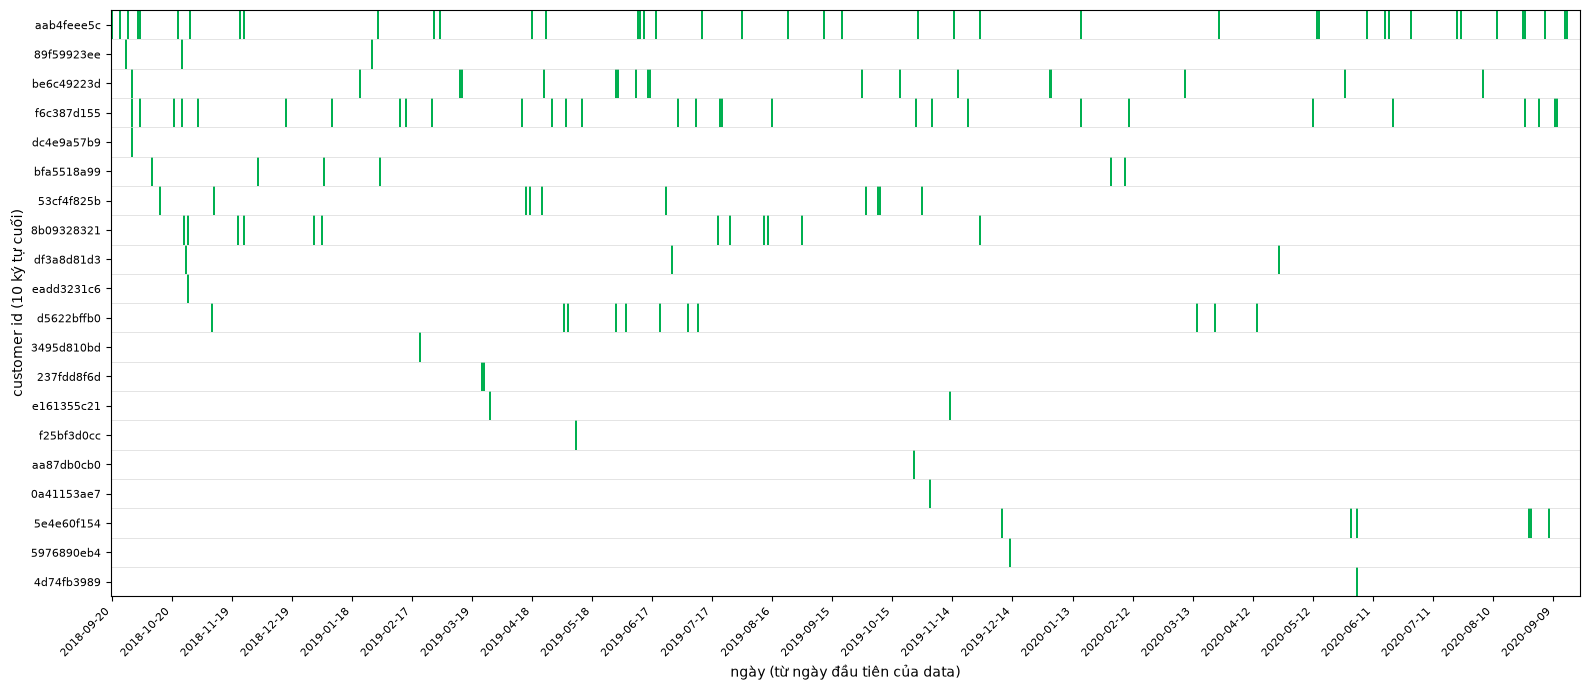

số ngày hoạt động mỗi khách: [42  3 17 30  1  6 10 12  3  1 11  1  2  2  1  1  1  6  1  1]


In [ ]:
M, ids, start = build_day_matrix(
    df, "customer_id", "t_dat",
    n_ids=20, min_days=1, sort_by=None)
plot_day_matrix(M, ids, start)
print("số ngày hoạt động mỗi khách:", M.sum(axis=1))

In [ ]:
df["customer_id"].unique()

<StringArray>
['000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318',
 '00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2',
 '00083cda041544b2fbb0e0d2905ad17da7cf1007526fb4c73235dccbbc132280',
 '0008968c0d451dbc5a9968da03196fe20051965edde7413775c4eb3be9abe9c2',
 '000aa7f0dc06cd7174389e76c9e132a67860c5f65f970699daccc14425ac31a8',
 '001127bffdda108579e6cb16080440e89bf1250a776c6e55f56e35e9ee029a8d',
 '001ea4e9c54f7e9c88811260d954edc059d596147e1cf8adc73323aebf571fd8',
 '001fd23db1109a94bba1319bb73df0b479059027c182da490e1161b34cd3af61',
 '0021da829b898f82269fc51feded4eac2129058ee95bd75bb1591e2eb14ecc79',
 '00228762ecff5b8d1ea6a2e52b96dafa198febddbc3bf350eb611f28e61ea6ce',
 ...
 'fd72c6498ad0ee844cce043bf2a8dca00a8491038a695bf2b7f3341de7f8323d',
 'fdba717e37a0a9738787d6a670361a8774d1ed3d00ffc1e2687fe0cb8c02a1e1',
 'fdcd7d55c497c620e7ffa7c557ec58da969cac10d3df3658b0cdc58a95ec25ef',
 'fdd8277a1a3f77b8c74a9a4f53e567d621f606948e20719cfd1215f22e88b306',
 'fdfd55a82781e

In [ ]:
def active_days_distribution(df, id_col, ts_col):
    x = pd.DataFrame({
        "id": df[id_col],
        "day": pd.to_datetime(df[ts_col]).dt.normalize(),
    }).dropna().drop_duplicates()                      # 1 khách + 1 ngày = 1 lần

    days_per_id = x.groupby("id").size()               # số ngày hoạt động mỗi khách

    dist = (days_per_id.value_counts().sort_index()
            .rename_axis("so_ngay_hoat_dong").rename("so_khach").reset_index())
    dist["ty_le_%"] = (dist["so_khach"] / dist["so_khach"].sum() * 100).round(2)
    dist["ty_le_tich_luy_%"] = dist["ty_le_%"].cumsum().round(2)
    return days_per_id, dist

days_per_id, dist = active_days_distribution(df, "customer_id", "t_dat")

print(f"Tổng số khách: {len(days_per_id):,}")
print(f"Trung bình: {days_per_id.mean():.2f} ngày/khách")
print(f"Trung vị:   {days_per_id.median():.0f} ngày/khách")
print(f"Lớn nhất:   {days_per_id.max()} ngày")
print(dist.to_string(index=False))

Tổng số khách: 1,362,281
Trung bình: 6.67 ngày/khách
Trung vị:   3 ngày/khách
Lớn nhất:   427 ngày
 so_ngay_hoat_dong  so_khach  ty_le_%  ty_le_tich_luy_%
                 1    447973    32.88             32.88
                 2    183116    13.44             46.32
                 3    113869     8.36             54.68
                 4     83255     6.11             60.79
                 5     65301     4.79             65.58
                 6     53964     3.96             69.54
                 7     46077     3.38             72.92
                 8     39569     2.90             75.82
                 9     34355     2.52             78.34
                10     29817     2.19             80.53
                11     26869     1.97             82.50
                12     23700     1.74             84.24
                13     20937     1.54             85.78
                14     18625     1.37             87.15
                15     16807     1.23             88.38
     

In [ ]:
import pandas as pd

def gap_between_active_days(df, id_col, ts_col):
    x = pd.DataFrame({
        "id": df[id_col],
        "day": pd.to_datetime(df[ts_col]).dt.normalize(),
    }).dropna().drop_duplicates().sort_values(["id", "day"])

    # khoảng cách (ngày) giữa 2 ngày hoạt động liên tiếp của cùng khách
    x["gap"] = x.groupby("id")["day"].diff().dt.days
    gaps = x.dropna(subset=["gap"])

    per_id = gaps.groupby("id")["gap"].agg(gap_tb="mean", gap_trung_vi="median", n_gap="size")
    return gaps["gap"], per_id

gaps, per_id = gap_between_active_days(df, "customer_id", "t_dat")

print(f"Khách tính được (≥ 2 ngày hoạt động): {len(per_id):,}")
print(f"[Gộp mọi khoảng cách] TB = {gaps.mean():.2f} ngày | trung vị = {gaps.median():.0f}")
print(f"[TB theo từng khách]  TB = {per_id['gap_tb'].mean():.2f} ngày | trung vị = {per_id['gap_tb'].median():.2f}")
print(gaps.describe(percentiles=[.25, .5, .75, .9]).round(2))

Khách tính được (≥ 2 ngày hoạt động): 914,308
[Gộp mọi khoảng cách] TB = 48.26 ngày | trung vị = 22
[TB theo từng khách]  TB = 90.34 ngày | trung vị = 60.67
count    7717898.00
mean          48.26
std           71.68
min            1.00
25%            7.00
50%           22.00
75%           58.00
90%          124.00
max          731.00
Name: gap, dtype: float64


In [ ]:
df.describe()

,article_id,price,sales_channel_id
count,3.178832e+07,3.178832e+07,3.178832e+07
mean,6.962272e+08,2.782927e-02,1.704028e+00
std,1.334480e+08,1.918113e-02,4.564786e-01
min,1.087750e+08,1.694915e-05,1.000000e+00
25%,6.328030e+08,1.581356e-02,1.000000e+00
50%,7.145820e+08,2.540678e-02,2.000000e+00
75%,7.865240e+08,3.388136e-02,2.000000e+00
max,9.562170e+08,5.915254e-01,2.000000e+00


In [ ]:
def missing_report(df):
    n = len(df)
    r = pd.DataFrame({
        "so_thieu": df.isna().sum(),
        "ty_le_%": (df.isna().mean() * 100).round(2),
        "so_gia_tri_khac_nhau": df.nunique(),
        "kieu": df.dtypes.astype(str),
    })
    return r[r["so_thieu"] > 0].sort_values("so_thieu", ascending=False) if r["so_thieu"].any() else r

print(missing_report(df))

                  so_thieu  ty_le_%  so_gia_tri_khac_nhau     kieu
t_dat                    0      0.0                   734      str
customer_id              0      0.0               1362281      str
article_id               0      0.0                104547    int64
price                    0      0.0                  9857  float64
sales_channel_id         0      0.0                     2    int64


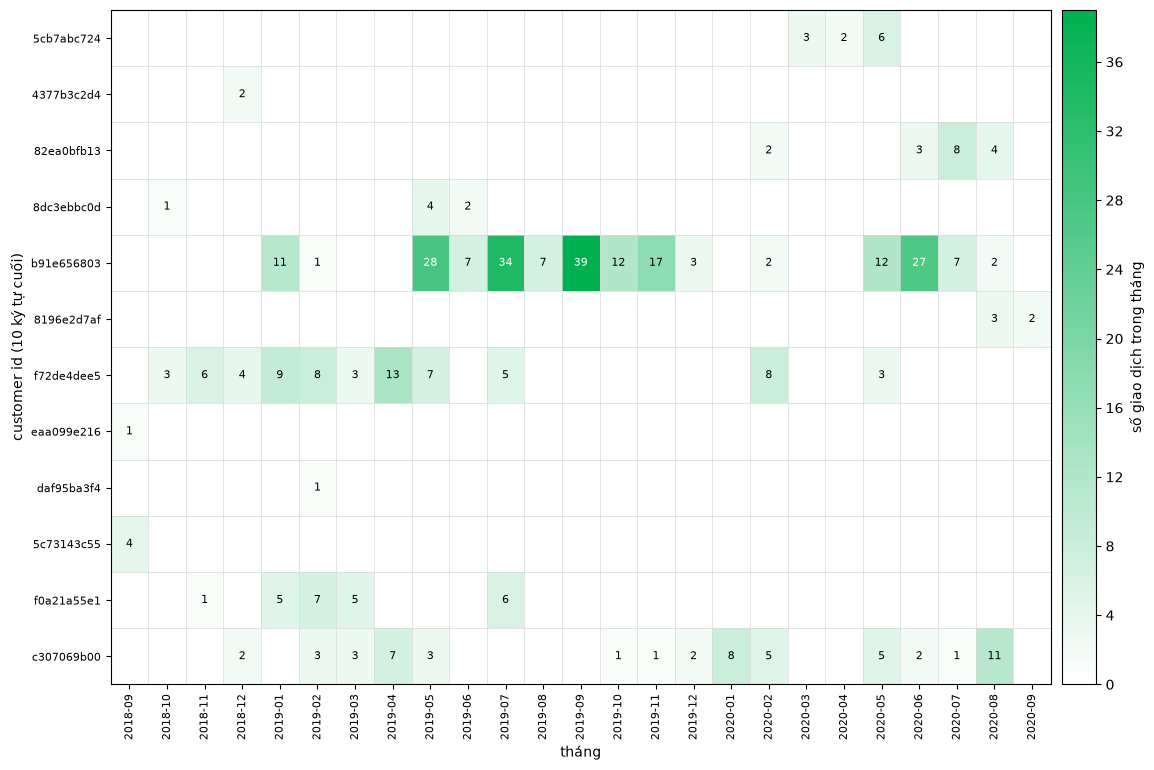

số tháng có giao dịch của từng khách:
5cb7abc724     3
4377b3c2d4     1
82ea0bfb13     4
8dc3ebbc0d     3
b91e656803    15
8196e2d7af     2
f72de4dee5    11
eaa099e216     1
daf95ba3f4     1
5c73143c55     1
f0a21a55e1     5
c307069b00    14
dtype: int64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

def plot_month_matrix(df, id_col, ts_col, start="2018-01", end="2020-12",
                      n_ids=12, min_active_months=1, unique_col=None,
                      seed=42, id_suffix=10, annotate=True):
    """
    Hàng = khách (ngẫu nhiên), cột = từng tháng từ start đến end,
    ô = số giao dịch của khách trong tháng đó.
    min_active_months: chỉ chọn khách có >= số tháng hoạt động này (1 = không lọc).
    unique_col: đếm số giá trị khác nhau của cột này (vd "Invoice") thay vì số dòng.
    """
    d = pd.DataFrame({"id": df[id_col], "ts": pd.to_datetime(df[ts_col], errors="coerce")})
    if unique_col:
        d["u"] = df[unique_col].values
    d = d.dropna(subset=["id", "ts"])
    d["m"] = d["ts"].dt.to_period("M")

    months = pd.period_range(start, end, freq="M")
    d = d[d["m"].between(months[0], months[-1])]

    g = d.groupby(["id", "m"])["u" if unique_col else "ts"]
    cnt = (g.nunique() if unique_col else g.size()).unstack(fill_value=0)
    cnt = cnt.reindex(columns=months, fill_value=0)

    pool = cnt.index[(cnt > 0).sum(axis=1) >= min_active_months]
    ids = pd.Series(pool).sample(min(n_ids, len(pool)), random_state=seed).tolist()
    M = cnt.loc[ids].to_numpy()

    fig, ax = plt.subplots(figsize=(len(months) * 0.5, len(ids) * 0.5 + 1.8))
    cmap = LinearSegmentedColormap.from_list("g", ["#ffffff", "#00B050"])
    im = ax.imshow(M, aspect="auto", cmap=cmap, vmin=0, vmax=max(1, M.max()),
                   interpolation="nearest")

    ax.set_xticks(np.arange(-0.5, len(months), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(ids), 1), minor=True)
    ax.grid(which="minor", color="#d9d9d9", linewidth=0.5)
    ax.tick_params(which="minor", length=0)

    ax.set_xticks(range(len(months)))
    ax.set_xticklabels([str(p) for p in months], rotation=90, fontsize=8)
    ax.set_yticks(range(len(ids)))
    ax.set_yticklabels([str(i)[-id_suffix:] for i in ids], fontsize=8)

    if annotate:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if M[i, j]:
                    ax.text(j, i, int(M[i, j]), ha="center", va="center", fontsize=8,
                            color="white" if M[i, j] > 0.6 * M.max() else "black")

    cb = fig.colorbar(im, ax=ax, pad=0.01)
    cb.set_label("số giao dịch trong tháng")
    cb.locator = plt.MaxNLocator(integer=True); cb.update_ticks()
    ax.set_xlabel("tháng")
    ax.set_ylabel(f"customer id ({id_suffix} ký tự cuối)")
    plt.tight_layout(); plt.show()
    return pd.DataFrame(M, index=[str(i)[-id_suffix:] for i in ids], columns=months.astype(str))

tbl = plot_month_matrix(df, "customer_id", "t_dat",start="2018-09", end="2020-09", n_ids=12)
print("số tháng có giao dịch của từng khách:")
print((tbl > 0).sum(axis=1))

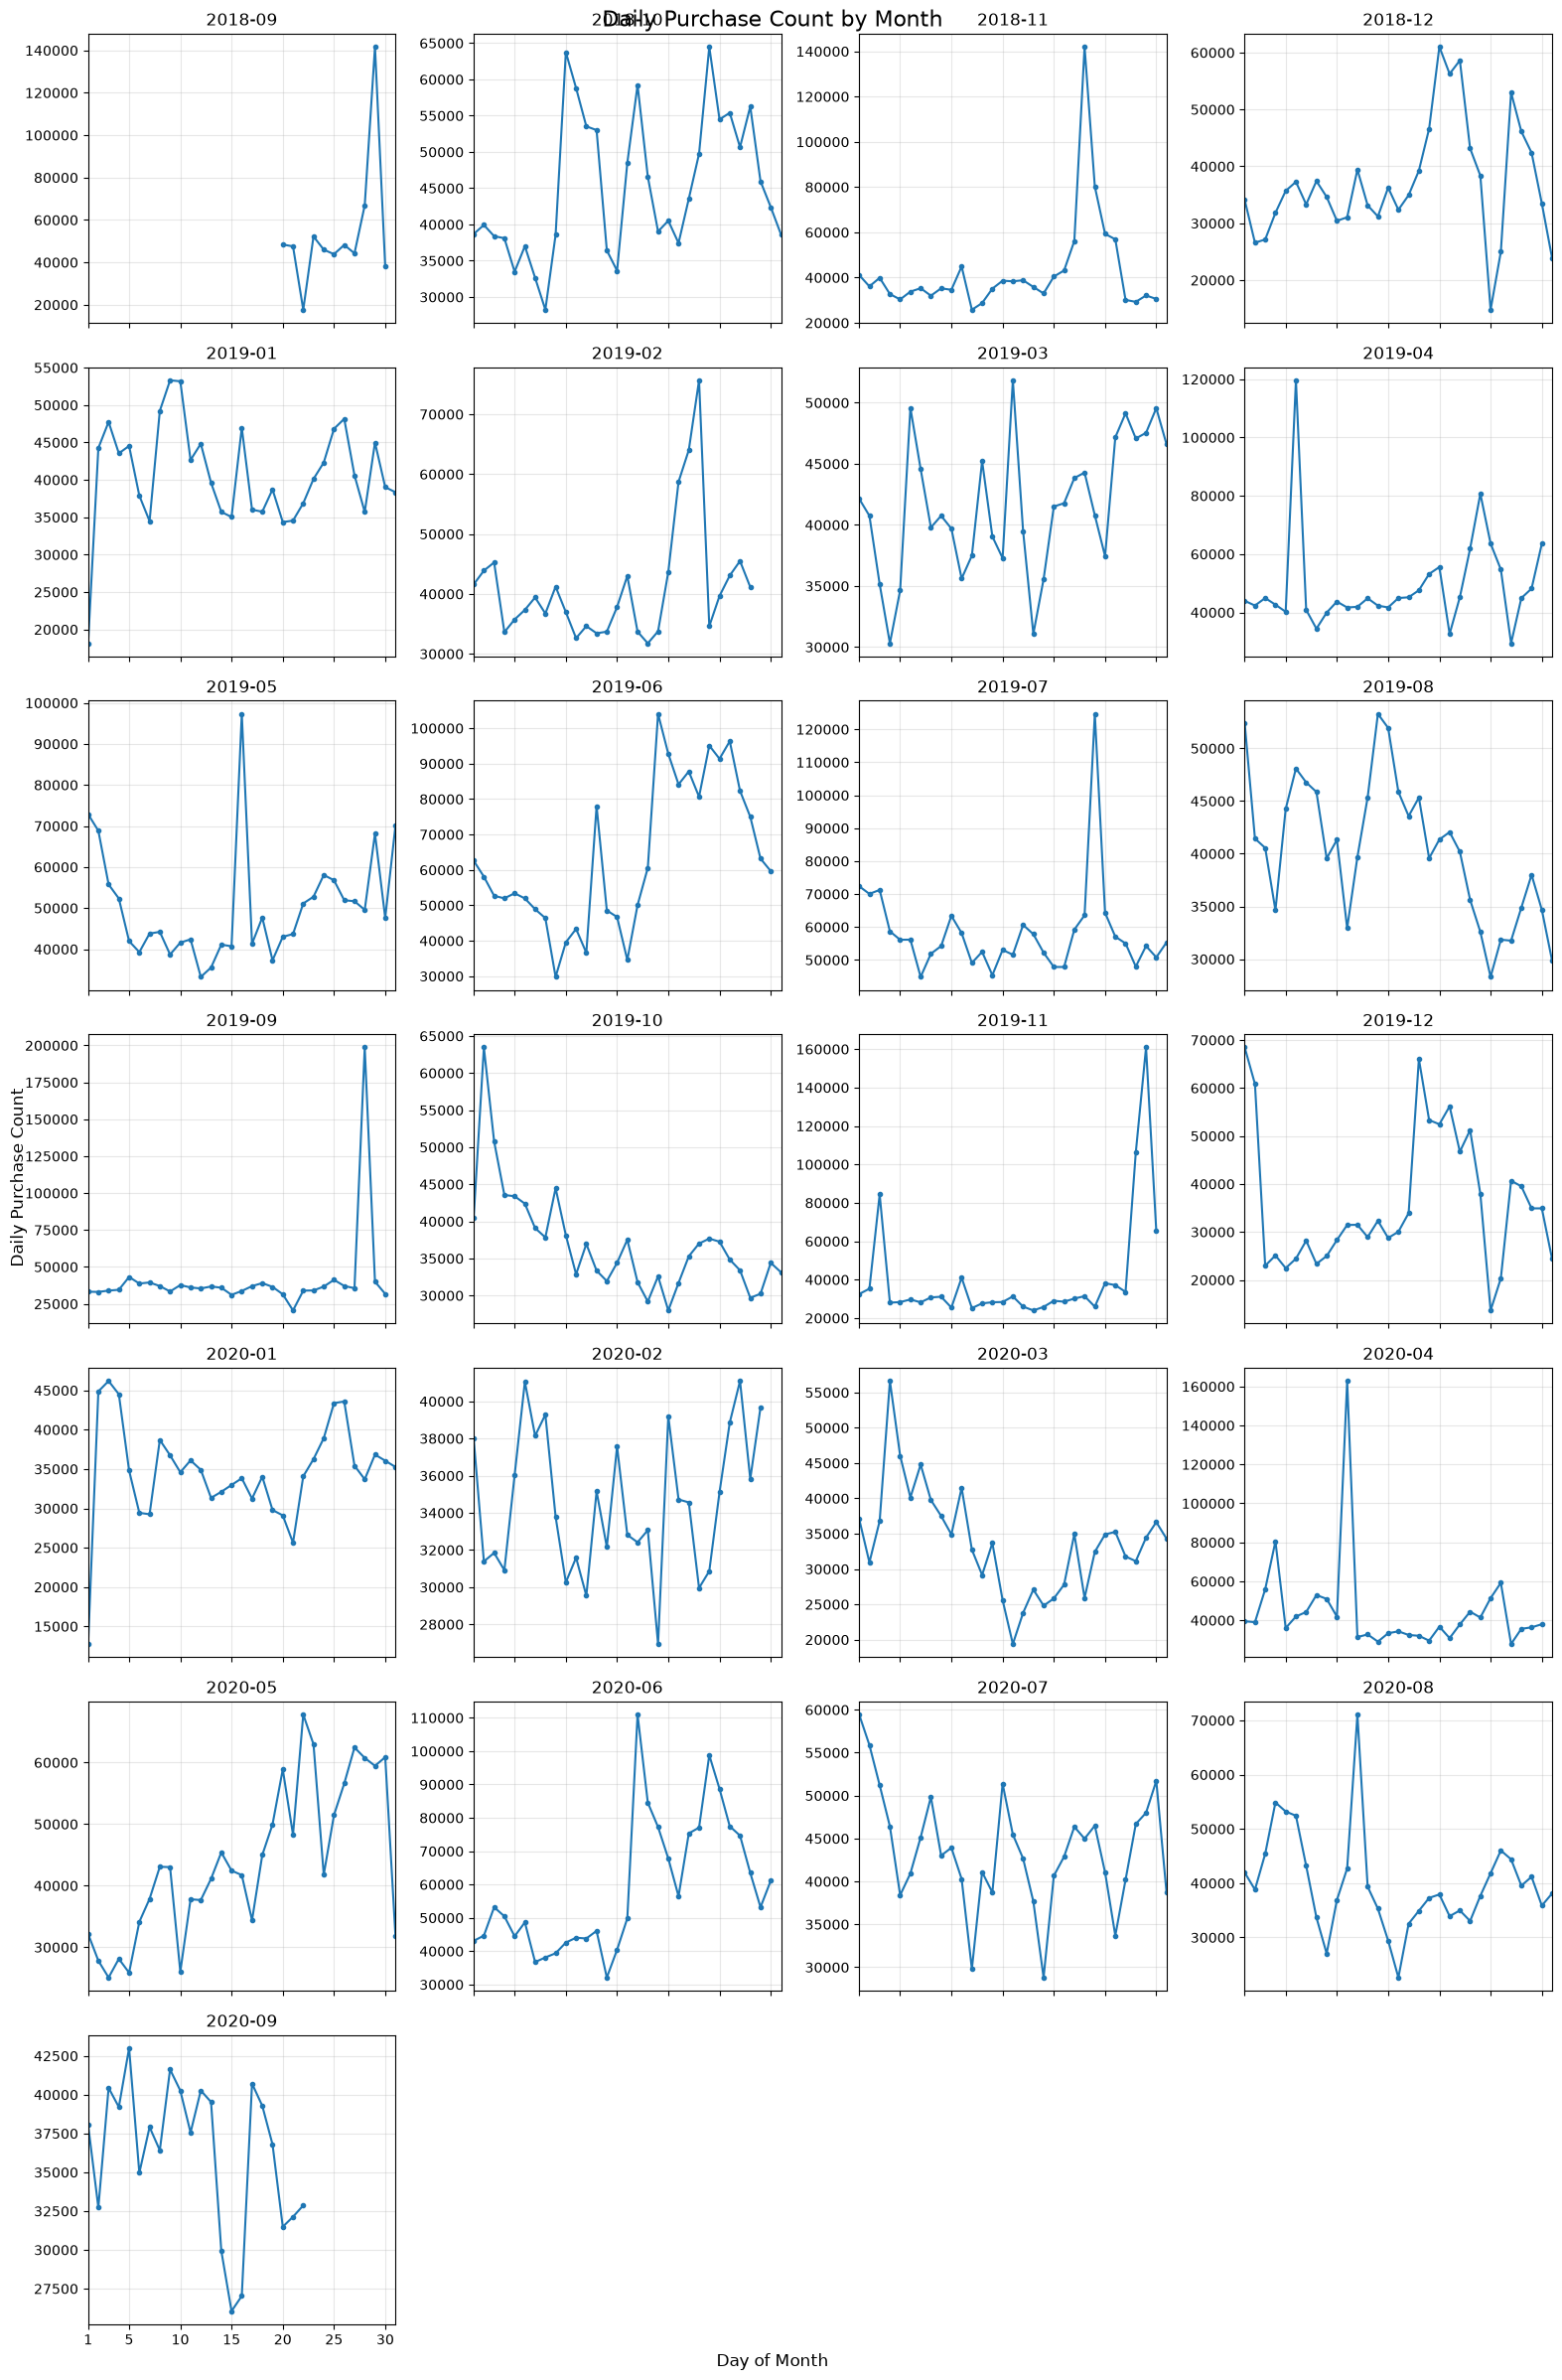

In [ ]:
import polars as pl
import matplotlib.pyplot as plt
import math

# Nếu t_dat đang là string thì mở dòng này
# df = df.with_columns(pl.col("t_dat").str.to_date("%Y-%m-%d"))

# 1. Đếm số lần mua theo từng ngày
daily_count = (
    df
    .group_by("t_dat")
    .agg(
        pl.len().alias("purchase_count")
    )
    .sort("t_dat")
    .with_columns([
        pl.col("t_dat").dt.day().alias("day"),
        pl.col("t_dat").dt.strftime("%Y-%m").alias("year_month"),
    ])
)

# 2. Lấy danh sách các tháng
months = (
    daily_count
    .select("year_month")
    .unique()
    .sort("year_month")
    .to_series()
    .to_list()
)

# 3. Tạo grid
n_cols = 4
n_rows = math.ceil(len(months) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 3.5 * n_rows),
    sharex=True
)

axes = axes.flatten()

# 4. Vẽ từng tháng
for i, month in enumerate(months):
    month_data = (
        daily_count
        .filter(pl.col("year_month") == month)
        .sort("day")
    )

    axes[i].plot(
        month_data["day"].to_list(),
        month_data["purchase_count"].to_list(),
        marker="o",
        markersize=3
    )

    axes[i].set_title(month)
    axes[i].set_xlim(1, 31)
    axes[i].set_xticks([1, 5, 10, 15, 20, 25, 30])
    axes[i].grid(alpha=0.3)

# 5. Ẩn các ô thừa
for j in range(len(months), len(axes)):
    axes[j].set_visible(False)

fig.supxlabel("Day of Month")
fig.supylabel("Daily Purchase Count")
fig.suptitle("Daily Purchase Count by Month", fontsize=16)

plt.tight_layout()
plt.show()

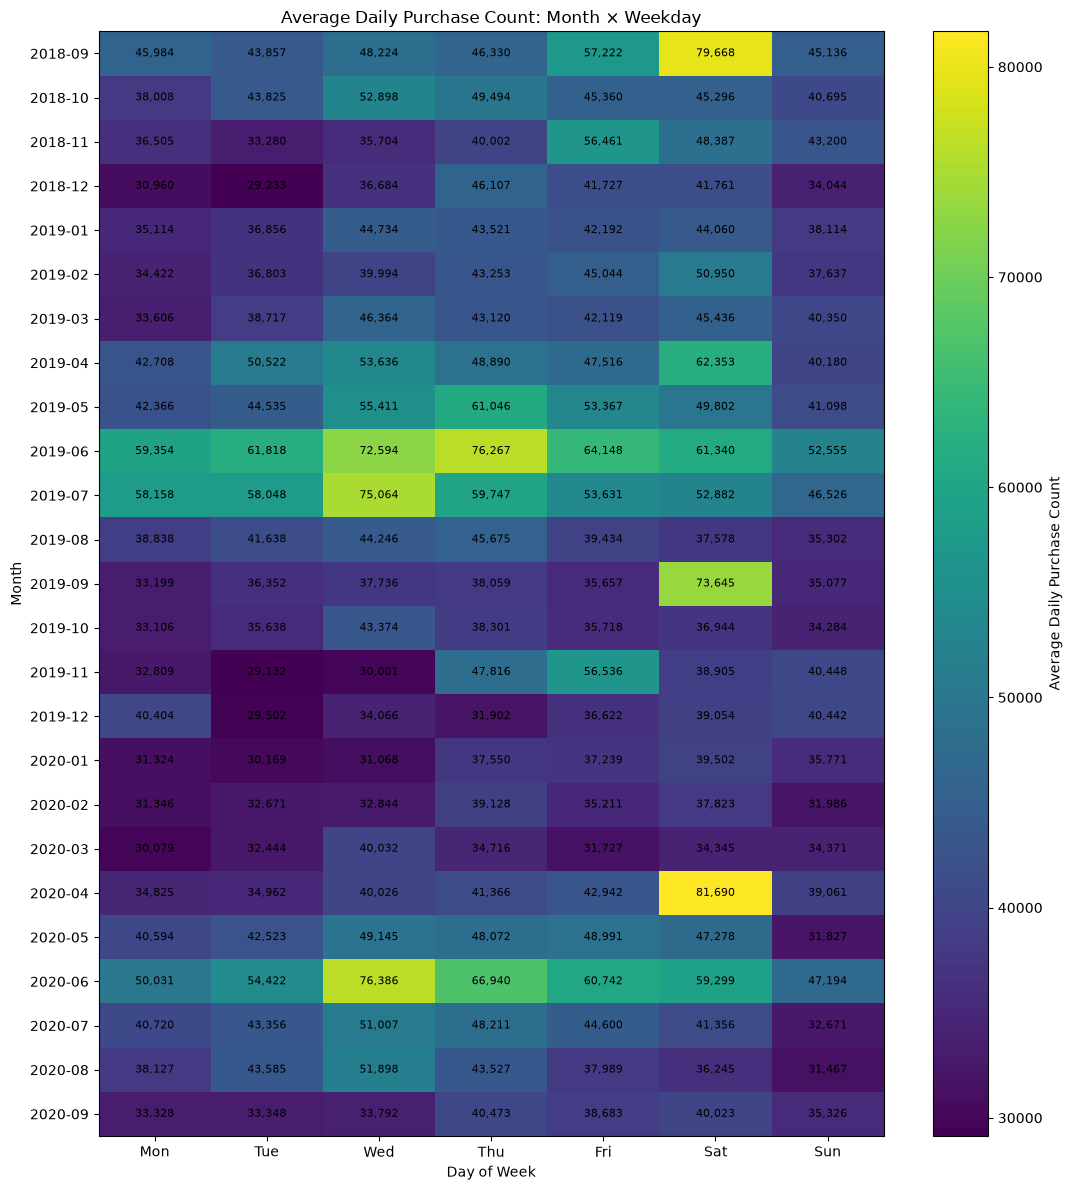

In [ ]:
import polars as pl
import matplotlib.pyplot as plt

# 1. Đếm số lượt mua theo từng ngày
daily_count = (
    df
    .group_by("t_dat")
    .agg(
        pl.len().alias("purchase_count")
    )
    .with_columns([
        pl.col("t_dat").dt.weekday().alias("weekday"),
        pl.col("t_dat").dt.strftime("%Y-%m").alias("year_month"),
    ])
)

# 2. Trung bình số lượt mua theo month x weekday
heatmap_data = (
    daily_count
    .group_by(["year_month", "weekday"])
    .agg(
        pl.col("purchase_count")
        .mean()
        .alias("avg_daily_purchase_count")
    )
    .sort(["year_month", "weekday"])
)

# 3. Pivot thành matrix
heatmap_df = (
    heatmap_data
    .pivot(
        values="avg_daily_purchase_count",
        index="year_month",
        on="weekday"
    )
    .sort("year_month")
)

months = heatmap_df["year_month"].to_list()

# Đảm bảo weekday đúng thứ tự 1 -> 7
weekday_cols = [str(i) for i in range(1, 8)]

values = (
    heatmap_df
    .select(weekday_cols)
    .to_numpy()
)

weekday_names = [
    "Mon", "Tue", "Wed",
    "Thu", "Fri", "Sat", "Sun"
]

# 4. Vẽ heatmap
fig, ax = plt.subplots(figsize=(11, 12))

im = ax.imshow(
    values,
    aspect="auto"
)

plt.colorbar(
    im,
    ax=ax,
    label="Average Daily Purchase Count"
)

ax.set_xticks(range(7))
ax.set_xticklabels(weekday_names)

ax.set_yticks(range(len(months)))
ax.set_yticklabels(months)

# 5. Ghi giá trị vào từng ô
for i in range(values.shape[0]):
    for j in range(values.shape[1]):

        value = values[i, j]

        if value == value:  # bỏ qua NaN
            ax.text(
                j,
                i,
                f"{value:,.0f}",
                ha="center",
                va="center",
                fontsize=8
            )

ax.set_xlabel("Day of Week")
ax.set_ylabel("Month")
ax.set_title(
    "Average Daily Purchase Count: Month × Weekday"
)

plt.tight_layout()
plt.show()

### Tập customer

In [ ]:
cus = pl.read_csv("customers.csv")
cus

customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
str,f64,f64,str,str,i64,str
"""00000dbacae5abe5e23885899a1fa4…",null,null,"""ACTIVE""","""NONE""",49,"""52043ee2162cf5aa7ee79974281641…"
"""0000423b00ade91418cceaf3b26c6a…",null,null,"""ACTIVE""","""NONE""",25,"""2973abc54daa8a5f8ccfe9362140c6…"
"""000058a12d5b43e67d225668fa1f8d…",null,null,"""ACTIVE""","""NONE""",24,"""64f17e6a330a85798e4998f62d0930…"
"""00005ca1c9ed5f5146b52ac8639a40…",null,null,"""ACTIVE""","""NONE""",54,"""5d36574f52495e81f019b680c843c4…"
"""00006413d8573cd20ed7128e53b7b1…",1.0,1.0,"""ACTIVE""","""Regularly""",52,"""25fa5ddee9aac01b35208d01736e57…"
…,…,…,…,…,…,…
"""ffffbbf78b6eaac697a8a5dfbfd2bf…",null,null,"""ACTIVE""","""NONE""",24,"""7aa399f7e669990daba2d92c577b52…"
"""ffffcd5046a6143d29a04fb8c424ce…",null,null,"""ACTIVE""","""NONE""",21,"""3f47f1279beb72215f4de557d950e0…"
"""ffffcf35913a0bee60e8741cb2b4e7…",1.0,1.0,"""ACTIVE""","""Regularly""",21,"""4563fc79215672cd6a863f2b4bf56b…"


In [ ]:
cus.dtypes

[String, Float64, Float64, String, String, Int64, String]

In [ ]:
report_cus = describe_dataset(cus)

DATASET OVERVIEW
{'shape': {'rows': 1371980, 'columns': 7}, 'memory_size': '214.99 MB', 'duplicate': {'duplicate_rows': 0, 'duplicate_pct': 0.0}, 'dtype_groups': {'numeric': ['FN', 'Active', 'age'], 'categorical': ['customer_id', 'club_member_status', 'fashion_news_frequency', 'postal_code'], 'datetime': [], 'boolean': [], 'other': []}}

COLUMN INFORMATION
shape: (7, 6)
┌────────────────────────┬─────────┬──────────┬─────────┬─────────────┬─────────┐
│ column                 ┆ dtype   ┆ non_null ┆ missing ┆ missing_pct ┆ unique  │
│ ---                    ┆ ---     ┆ ---      ┆ ---     ┆ ---         ┆ ---     │
│ str                    ┆ str     ┆ i64      ┆ i64     ┆ f64         ┆ i64     │
╞════════════════════════╪═════════╪══════════╪═════════╪═════════════╪═════════╡
│ customer_id            ┆ String  ┆ 1371980  ┆ 0       ┆ 0.0         ┆ 1371980 │
│ FN                     ┆ Float64 ┆ 476930   ┆ 895050  ┆ 65.24       ┆ 1       │
│ Active                 ┆ Float64 ┆ 464404   ┆ 90757

In [ ]:
report_cus = describe_dataset(cus)

DATASET OVERVIEW
{'shape': {'rows': 1371980, 'columns': 7}, 'memory_size': '214.99 MB', 'duplicate': {'duplicate_rows': 0, 'duplicate_pct': 0.0}, 'dtype_groups': {'numeric': ['FN', 'Active', 'age'], 'categorical': ['customer_id', 'club_member_status', 'fashion_news_frequency', 'postal_code'], 'datetime': [], 'boolean': [], 'other': []}}

COLUMN INFORMATION
shape: (7, 6)
┌────────────────────────┬─────────┬──────────┬─────────┬─────────────┬─────────┐
│ column                 ┆ dtype   ┆ non_null ┆ missing ┆ missing_pct ┆ unique  │
│ ---                    ┆ ---     ┆ ---      ┆ ---     ┆ ---         ┆ ---     │
│ str                    ┆ str     ┆ i64      ┆ i64     ┆ f64         ┆ i64     │
╞════════════════════════╪═════════╪══════════╪═════════╪═════════════╪═════════╡
│ customer_id            ┆ String  ┆ 1371980  ┆ 0       ┆ 0.0         ┆ 1371980 │
│ FN                     ┆ Float64 ┆ 476930   ┆ 895050  ┆ 65.24       ┆ 1       │
│ Active                 ┆ Float64 ┆ 464404   ┆ 90757

#### Tập arti

In [ ]:
arti = pl.read_csv("articles.csv")
arti.head()

article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
i64,i64,str,i64,str,str,i64,str,i64,str,i64,str,i64,str,i64,str,str,str,i64,str,i64,str,i64,str,str
108775015,108775,"""Strap top""",253,"""Vest top""","""Garment Upper body""",1010016,"""Solid""",9,"""Black""",4,"""Dark""",5,"""Black""",1676,"""Jersey Basic""","""A""","""Ladieswear""",1,"""Ladieswear""",16,"""Womens Everyday Basics""",1002,"""Jersey Basic""","""Jersey top with narrow shoulde…"
108775044,108775,"""Strap top""",253,"""Vest top""","""Garment Upper body""",1010016,"""Solid""",10,"""White""",3,"""Light""",9,"""White""",1676,"""Jersey Basic""","""A""","""Ladieswear""",1,"""Ladieswear""",16,"""Womens Everyday Basics""",1002,"""Jersey Basic""","""Jersey top with narrow shoulde…"
108775051,108775,"""Strap top (1)""",253,"""Vest top""","""Garment Upper body""",1010017,"""Stripe""",11,"""Off White""",1,"""Dusty Light""",9,"""White""",1676,"""Jersey Basic""","""A""","""Ladieswear""",1,"""Ladieswear""",16,"""Womens Everyday Basics""",1002,"""Jersey Basic""","""Jersey top with narrow shoulde…"
110065001,110065,"""OP T-shirt (Idro)""",306,"""Bra""","""Underwear""",1010016,"""Solid""",9,"""Black""",4,"""Dark""",5,"""Black""",1339,"""Clean Lingerie""","""B""","""Lingeries/Tights""",1,"""Ladieswear""",61,"""Womens Lingerie""",1017,"""Under-, Nightwear""","""Microfibre T-shirt bra with un…"
110065002,110065,"""OP T-shirt (Idro)""",306,"""Bra""","""Underwear""",1010016,"""Solid""",10,"""White""",3,"""Light""",9,"""White""",1339,"""Clean Lingerie""","""B""","""Lingeries/Tights""",1,"""Ladieswear""",61,"""Womens Lingerie""",1017,"""Under-, Nightwear""","""Microfibre T-shirt bra with un…"


In [ ]:
arti.dtypes

[Int64,
 Int64,
 String,
 Int64,
 String,
 String,
 Int64,
 String,
 Int64,
 String,
 Int64,
 String,
 Int64,
 String,
 Int64,
 String,
 String,
 String,
 Int64,
 String,
 Int64,
 String,
 Int64,
 String,
 String]

In [ ]:
report_arti = describe_dataset(arti)

DATASET OVERVIEW
{'shape': {'rows': 105542, 'columns': 25}, 'memory_size': '36.38 MB', 'duplicate': {'duplicate_rows': 0, 'duplicate_pct': 0.0}, 'dtype_groups': {'numeric': ['article_id', 'product_code', 'product_type_no', 'graphical_appearance_no', 'colour_group_code', 'perceived_colour_value_id', 'perceived_colour_master_id', 'department_no', 'index_group_no', 'section_no', 'garment_group_no'], 'categorical': ['prod_name', 'product_type_name', 'product_group_name', 'graphical_appearance_name', 'colour_group_name', 'perceived_colour_value_name', 'perceived_colour_master_name', 'department_name', 'index_code', 'index_name', 'index_group_name', 'section_name', 'garment_group_name', 'detail_desc'], 'datetime': [], 'boolean': [], 'other': []}}

COLUMN INFORMATION
shape: (25, 6)
┌────────────────────┬────────┬──────────┬─────────┬─────────────┬────────┐
│ column             ┆ dtype  ┆ non_null ┆ missing ┆ missing_pct ┆ unique │
│ ---                ┆ ---    ┆ ---      ┆ ---     ┆ ---      

In [21]:
import matplotlib.pyplot as plt
from src.eda.visualization import (
    plot_active_periods_per_entity,
    plot_entity_time_matrix,
    plot_missing_values,
    plot_records_over_time,
    plot_records_per_entity,
)

NameError: name 'plt' is not defined

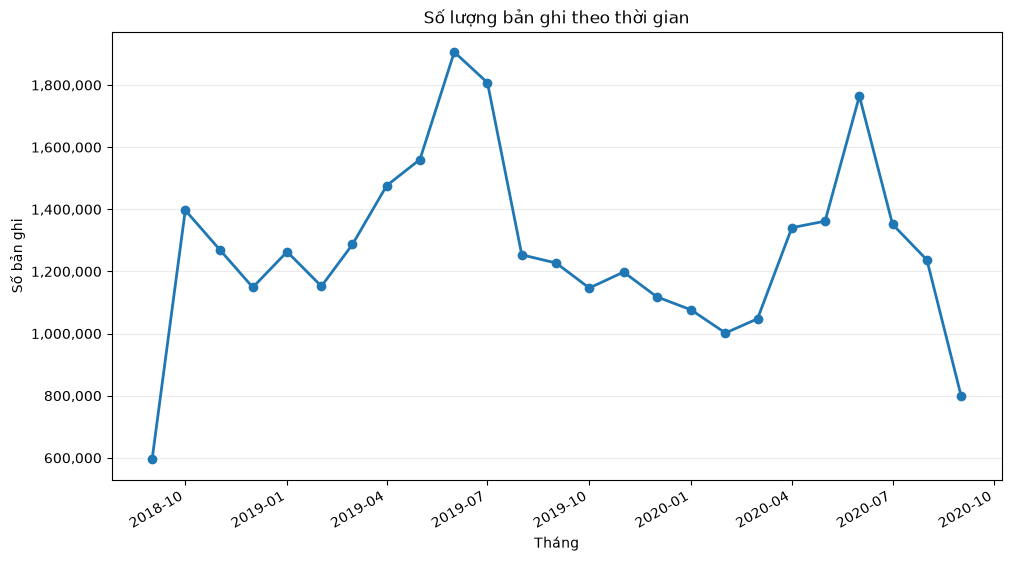

In [18]:
# 1. Chạy describe_temporal
temp_report = describe_temporal(transactions_train, time_col="t_dat")
# 2. Vẽ biểu đồ theo tháng
fig_time = plot_records_over_time(temp_report["monthly_records"])
plt.show()

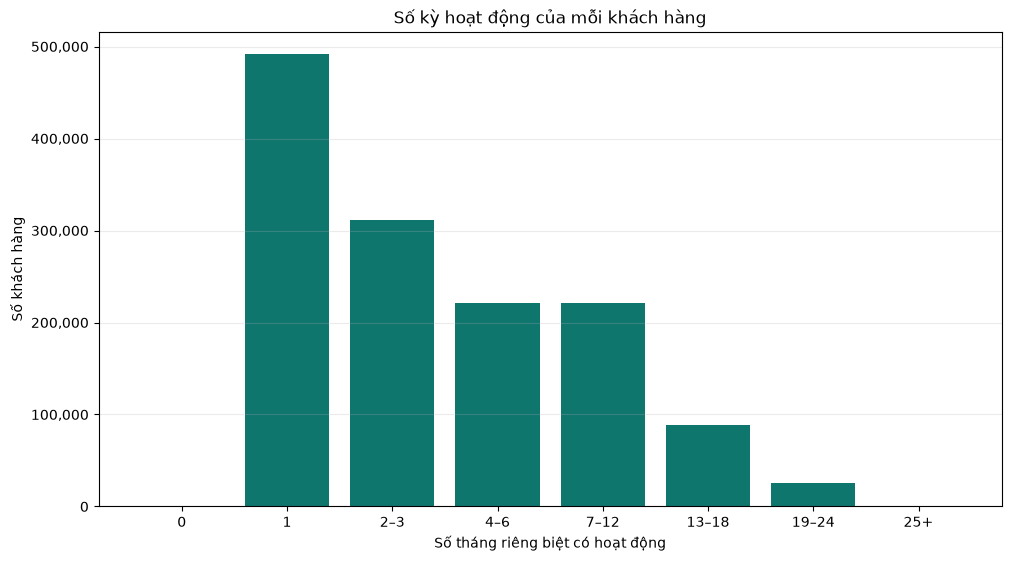

In [22]:
entity_history = trans_entity["entity_history"]
# 2. Vẽ phân phối số lượng bản ghi trên mỗi khách (thang Log do lệch đuôi dài)
fig_periods = plot_active_periods_per_entity(entity_history)
plt.show()

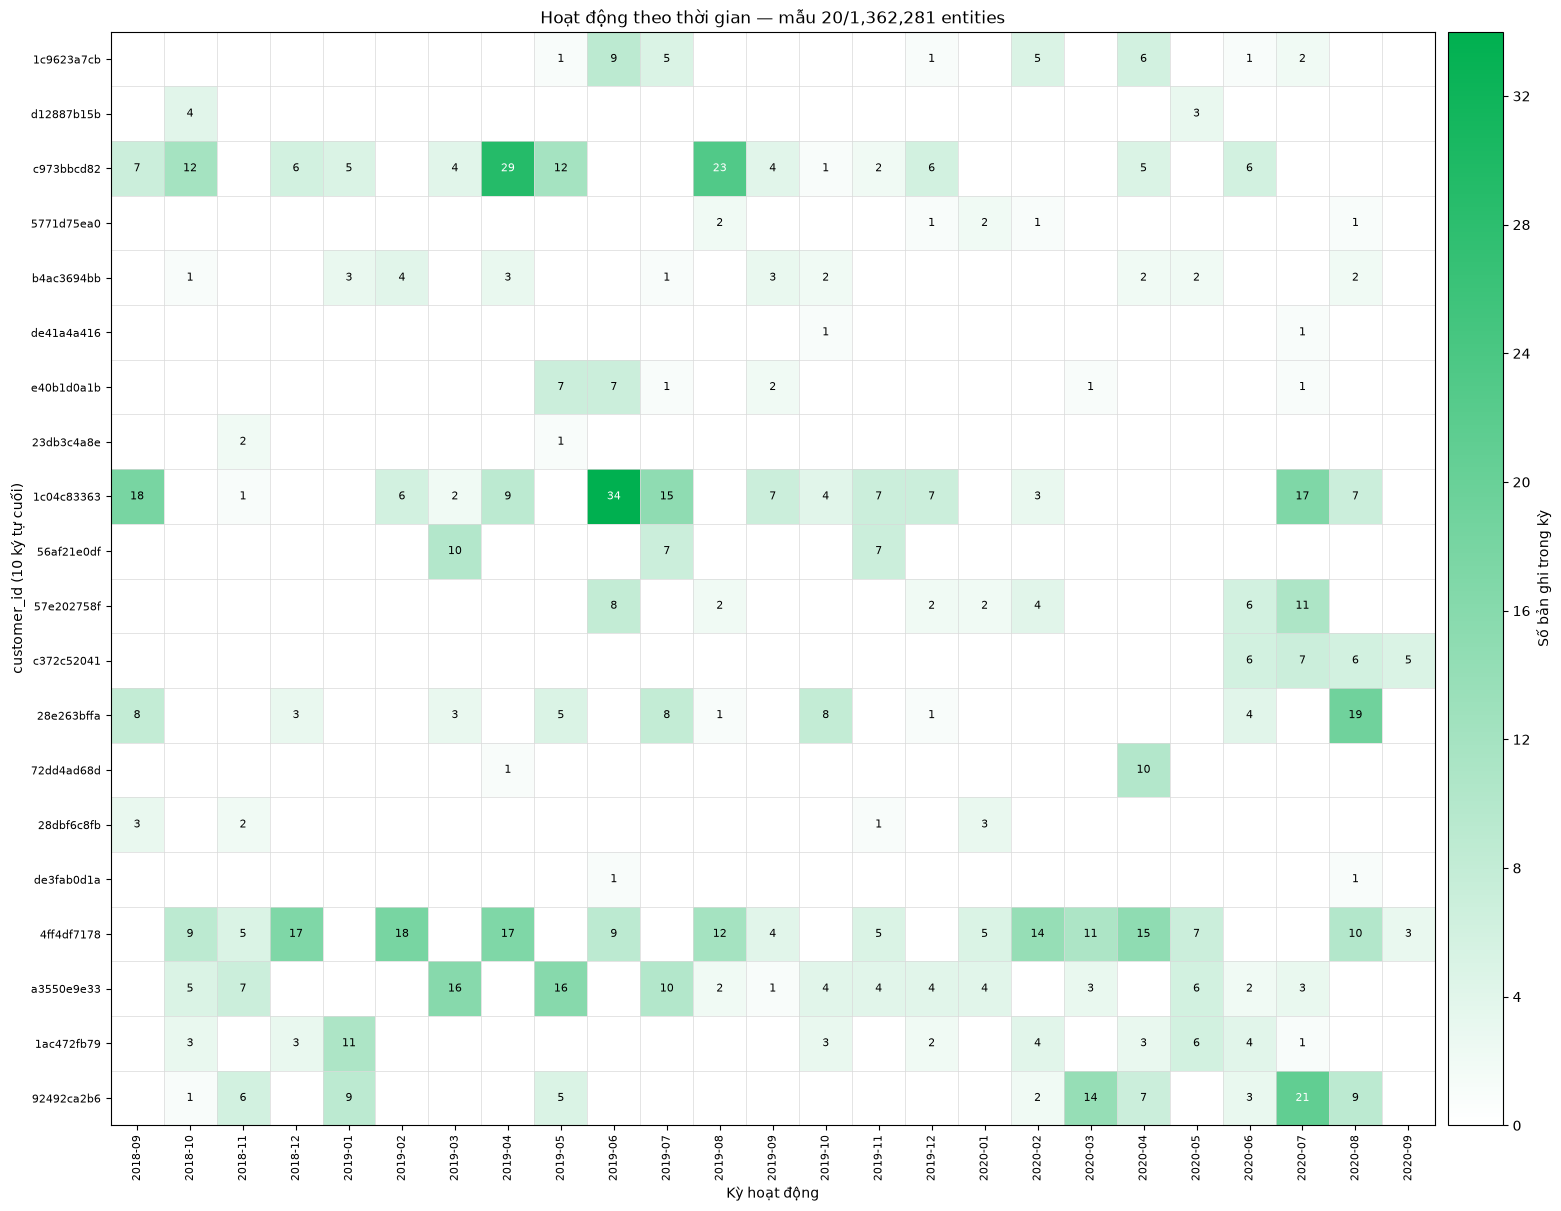

ActivityCoverage(n_entities=1362281, n_eligible_entities=870722, n_periods=25, n_active_entity_periods=6230341, coverage_pct=18.29384980044499, sample_size=20)


In [24]:
matrix_res = plot_entity_time_matrix(
    transactions_train,
    entity_col="customer_id",
    timestamp_col="t_dat",
    freq="1mo",             # gom theo tháng
    sample_size=20,         # lấy mẫu 50 khách hàng để hiển thị rõ heatmap
    min_active_periods=2,   # chỉ lấy mẫu những khách có hoạt động từ 2 tháng trở lên
    seed=42,
)

# Hiển thị biểu đồ Heatmap
plt.show()

# Bạn cũng có thể in độ phủ (coverage) toàn tập dữ liệu
print(matrix_res.global_coverage)